# Week 4 - Self-Driving Car: Training, Testing & Visualising Predictions

**Topics (record sections i, j)**
* i. Train the model with the generators, plot the loss curves
* j. Evaluate on the test set, compare predicted vs actual steering, compare with the baseline, save the model

## Setup + recap of Weeks 1-3
Everything needed is re-created here so the notebook runs on its own.

In [1]:
import os, random, ntpath, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Dense, MaxPooling2D, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

random.seed(0); np.random.seed(0); tf.random.set_seed(0)

datadir = "data/selfdrive"
if not os.path.exists(os.path.join(datadir, "driving_log.csv")):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Aman-py/data.git", datadir], check=True)
print("Dataset folder ready:", os.path.exists(datadir))

columns = ["center", "left", "right", "steering", "throttle", "reverse", "speed"]
dataset = pd.read_csv(os.path.join(datadir, "driving_log.csv"), names=columns)

# ---- Recap of Weeks 1-2: load -> clean paths -> balance -> split ----
num_bins, threshold = 25, 500

def removePath(path):
    return ntpath.split(path)[1]

for col in ["center", "left", "right"]:
    dataset[col] = dataset[col].apply(removePath)

hist, bins = np.histogram(dataset["steering"], num_bins)
bin_id = np.clip(np.digitize(dataset["steering"], bins[1:-1]), 0, num_bins - 1)   # each sample -> exactly one bin
remove_list = []
for i in range(num_bins):
    idx = shuffle(np.where(bin_id == i)[0], random_state=42)
    remove_list.extend(idx[threshold:])            # drop only the surplus above the threshold
dataset = dataset.drop(dataset.index[remove_list]).reset_index(drop=True)

def loadImageSteering(datadir, df):
    paths = [os.path.join(datadir, c) for c in df["center"]]
    return np.asarray(paths), df["steering"].astype(float).to_numpy()

imagePath, steeringPath = loadImageSteering(os.path.join(datadir, "IMG"), dataset)
x_train, x_test, y_train, y_test = train_test_split(imagePath, steeringPath, test_size=0.2, random_state=6)
baseline_mse = np.mean((y_test - np.mean(y_train)) ** 2)
print("Balanced dataset:", len(dataset), "| train:", len(x_train), "| test:", len(x_test))

def imagePreprocessing(img_path):
    img = mpimg.imread(img_path)                    # read image (RGB)
    img = img[60:135, :, :]                         # crop away sky and car bonnet
    img = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)      # RGB -> YUV (as in NVIDIA's paper)
    img = cv2.GaussianBlur(img, (3, 3), 0)          # light denoising
    img = cv2.resize(img, (200, 66))                # NVIDIA input size (width, height)
    img = img / 255.0                               # scale pixels to [0, 1]
    return img

def batch_generator(image_paths, steering_values, batch_size=32):
    while True:                                     # Keras keeps pulling batches, so loop forever
        indices = np.random.permutation(len(image_paths))      # reshuffle every pass
        for start in range(0, len(image_paths), batch_size):
            batch_indices = indices[start:start + batch_size]
            images, angles = [], []
            for index in batch_indices:
                images.append(imagePreprocessing(image_paths[index]))
                angles.append(steering_values[index])
            yield np.array(images, dtype=np.float32), np.array(angles, dtype=np.float32)

def nvidiaModel():
    model = Sequential([
        Input(shape=(66, 200, 3)),
        Conv2D(24, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(36, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(48, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(64, (3, 3), activation="elu"),
        Conv2D(64, (3, 3), activation="elu"),
        Dropout(0.5),
        Flatten(),
        Dense(100, activation="elu"), Dropout(0.5),
        Dense(50, activation="elu"),  Dropout(0.5),
        Dense(10, activation="elu"),  Dropout(0.5),
        Dense(1),                                   # regression output: steering angle
    ])
    model.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
    return model

batch_size = 32
train_generator = batch_generator(x_train, y_train, batch_size)
validation_generator = batch_generator(x_test, y_test, batch_size)
model = nvidiaModel()
print("Baseline MSE (mean predictor):", baseline_mse)

Dataset folder ready: True
Balanced dataset: 2305 | train: 1844 | test: 461


Baseline MSE (mean predictor): 0.11740117013233528


## i. Train the model
A generator has no length, so we must say how many batches make one **epoch**:

* `steps_per_epoch = len(train) // batch_size`
* `validation_steps = len(test) // batch_size`

Each epoch the network sees every training image once, adjusts its weights to reduce the MSE, then measures MSE on the validation images.

In [2]:
steps_per_epoch = len(x_train) // batch_size
validation_steps = len(x_test) // batch_size
print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

Steps per epoch: 57
Validation steps: 14


In [3]:
history = model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    epochs=30,
    verbose=2,
)

C:\Users\Roshan Sai\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/30


57/57 - 9s - 158ms/step - loss: 0.4086 - val_loss: 0.1133


Epoch 2/30


57/57 - 3s - 60ms/step - loss: 0.1240 - val_loss: 0.0953


...

57/57 - 5s - 84ms/step - loss: 0.0504 - val_loss: 0.0881


Epoch 29/30


57/57 - 5s - 87ms/step - loss: 0.0475 - val_loss: 0.0857


Epoch 30/30


57/57 - 6s - 103ms/step - loss: 0.0425 - val_loss: 0.0776


### Loss curves
* **Training loss** falling = the network is learning.
* **Validation loss** is the honest measure: if it stops falling (or rises) while training loss keeps dropping, the model is over-fitting.

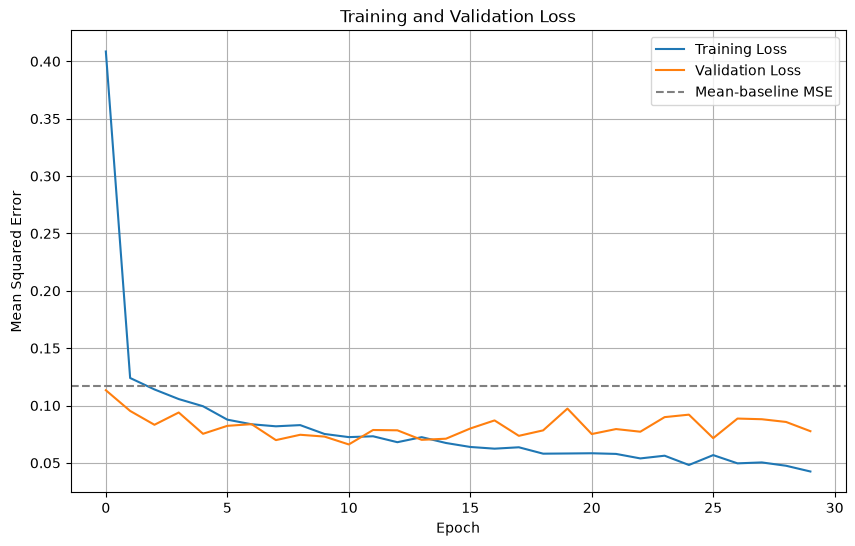

Final training loss: 0.0425
Final validation loss: 0.07764


In [4]:
plt.figure(figsize=(10, 6))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.axhline(baseline_mse, color="gray", linestyle="--", label="Mean-baseline MSE")
plt.title("Training and Validation Loss"); plt.xlabel("Epoch"); plt.ylabel("Mean Squared Error")
plt.legend(); plt.grid(True); plt.show()
print("Final training loss:", round(history.history["loss"][-1], 5))
print("Final validation loss:", round(history.history["val_loss"][-1], 5))

## j. Test and visualise
Pre-process the whole test set into one array and evaluate. (Training loss is higher than it could be because dropout is active during training but switched off in `evaluate`/`predict`.)

In [5]:
x_test_processed = np.array([imagePreprocessing(p) for p in x_test], dtype=np.float32)
print("Test data shape:", x_test_processed.shape)

test_loss = model.evaluate(x_test_processed, y_test, verbose=0)
print("Test MSE:", test_loss)

Test data shape: (461, 66, 200, 3)


Test MSE: 0.08612313866615295


In [6]:
predictions = model.predict(x_test_processed, verbose=0).flatten()

comparison = pd.DataFrame({"Actual Steering": y_test, "Predicted Steering": predictions})
comparison["Abs Error"] = (comparison["Actual Steering"] - comparison["Predicted Steering"]).abs()
print("Mean absolute error:", comparison["Abs Error"].mean().round(4))
comparison.head(10)

Mean absolute error: 0.2064


,Actual Steering,Predicted Steering,Abs Error
0,0.000000,-0.423103,0.423103
1,-0.199455,-0.260063,0.060608
2,-0.149508,-0.198972,0.049463
3,-0.185046,0.143347,0.328393
4,0.000000,-0.006996,0.006996
5,-0.106884,-0.206558,0.099674
6,0.376845,-0.001468,0.378313
7,0.291775,0.072853,0.218922
8,-0.510579,-0.025407,0.485172
9,0.000000,-0.201758,0.201758


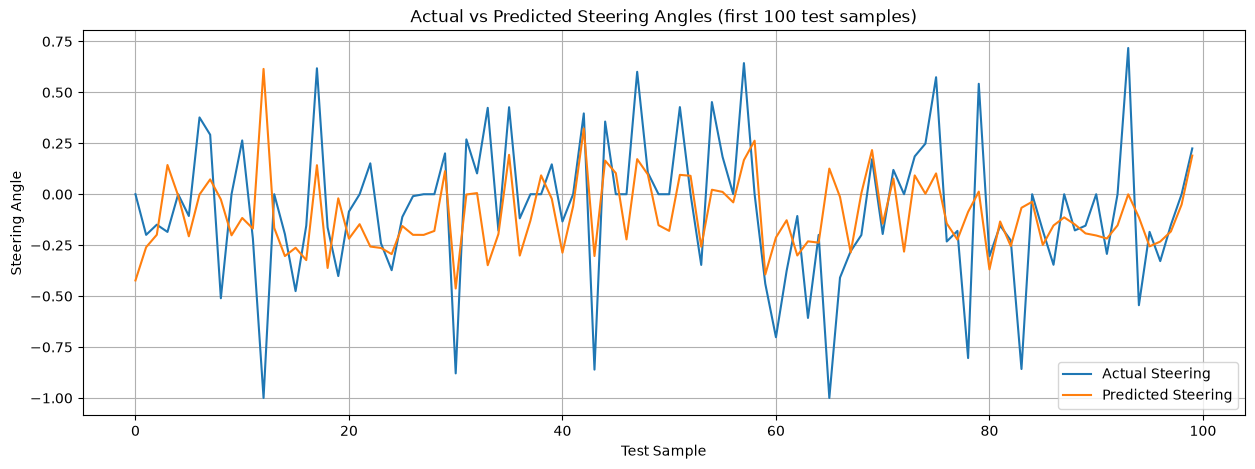

In [7]:
plt.figure(figsize=(15, 5))
plt.plot(y_test[:100], label="Actual Steering")
plt.plot(predictions[:100], label="Predicted Steering")
plt.title("Actual vs Predicted Steering Angles (first 100 test samples)")
plt.xlabel("Test Sample"); plt.ylabel("Steering Angle"); plt.legend(); plt.grid(True); plt.show()

A scatter plot is another view: a perfect model puts every point on the diagonal.

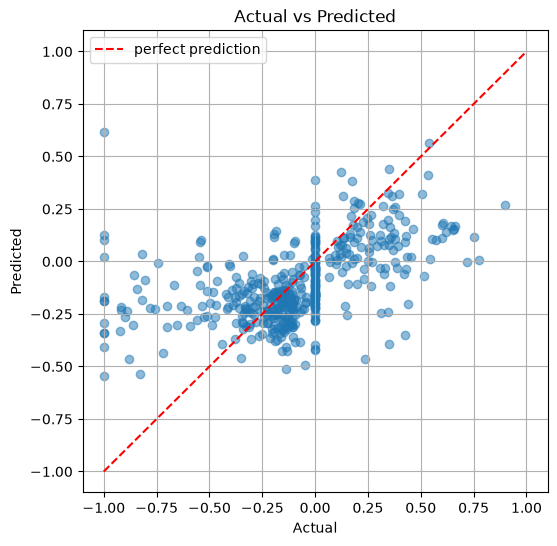

Correlation actual vs predicted: 0.503


In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.5)
plt.plot([-1, 1], [-1, 1], "r--", label="perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs Predicted"); plt.legend(); plt.grid(True); plt.show()
print("Correlation actual vs predicted:", np.corrcoef(y_test, predictions)[0, 1].round(3))

### Images with their predictions

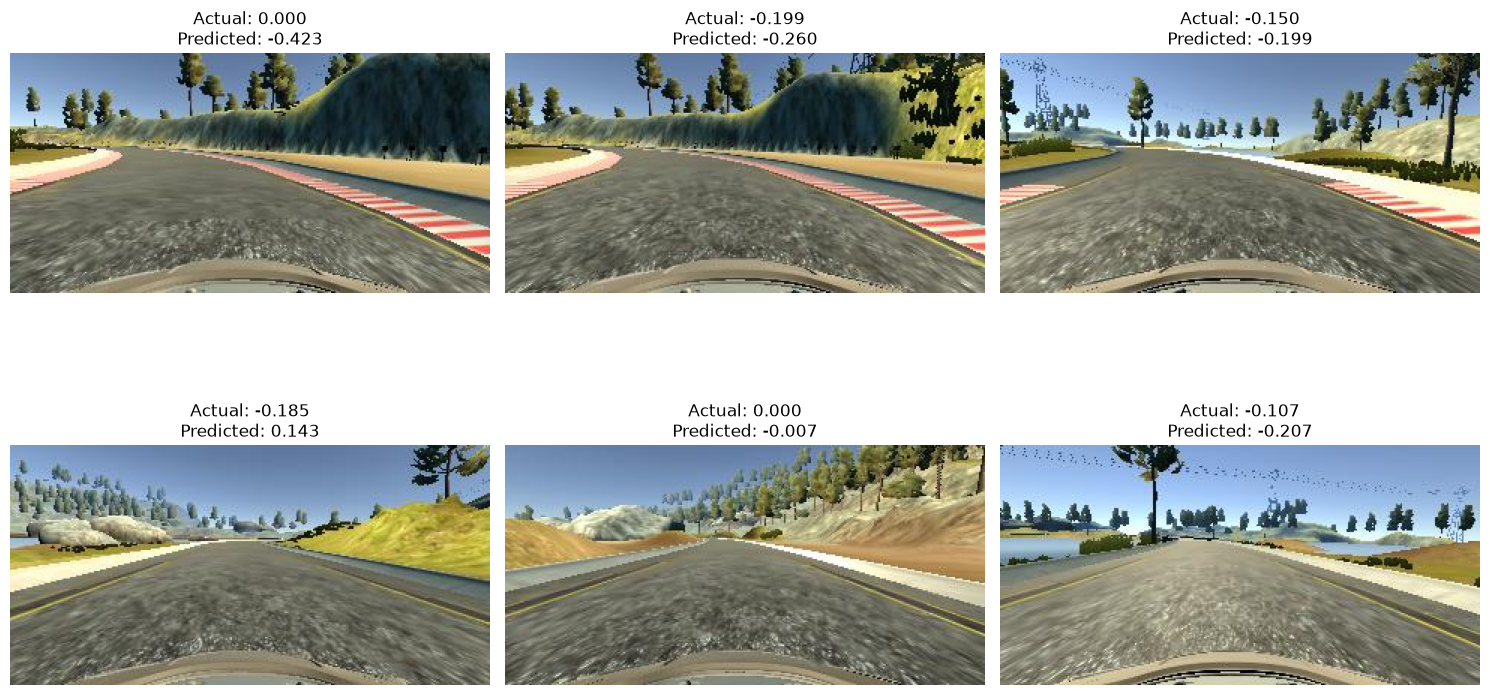

In [9]:
plt.figure(figsize=(15, 9))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(mpimg.imread(x_test[i])); plt.axis("off")
    plt.title(f"Actual: {y_test[i]:.3f}\nPredicted: {predictions[i]:.3f}")
plt.tight_layout(); plt.show()

### Baseline vs CNN
This is the key comparison. A model only adds value if its MSE is **lower than the baseline**. Because the dataset is balanced, the baseline now has real errors to make, so the comparison is meaningful.

In [10]:
print("Mean Baseline MSE :", baseline_mse)
print("NVIDIA CNN Test MSE:", test_loss)
print("Improvement over baseline:", round((1 - test_loss / baseline_mse) * 100, 1), "%")

Mean Baseline MSE : 0.11740117013233528
NVIDIA CNN Test MSE: 0.08612313866615295
Improvement over baseline: 26.6 %


### Save the model
Modern Keras (3.x) saves to the `.keras` format; the old `car.h5` HDF5 format is deprecated. We save, reload, and confirm identical predictions.

In [11]:
model.save("car.keras")
print("Model saved successfully.")

reloaded = tf.keras.models.load_model("car.keras")
print("Reloaded predictions identical:", np.allclose(reloaded.predict(x_test_processed[:10], verbose=0).flatten(), predictions[:10], atol=1e-5))

Model saved successfully.

Reloaded predictions identical: True


## Summary & ideas for extensions
* Trained the NVIDIA CNN and evaluated it against the mean baseline.
* Possible extensions: use the **left/right cameras** with a +/-0.2 steering correction, add **data augmentation** (flip image and negate steering, random brightness, shifts), train longer, or use more data.